In [3]:
print("Welcome to Student Performance Analysis Project!")
print("My first AI and Machine Learning Project")

Welcome to Student Performance Analysis Project!
My first AI and Machine Learning Project


In [4]:
!pip install pandas numpy matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries installed successfully!")

All libraries installed successfully!


In [6]:
import pandas as pd

data = {
    'Name': ['Anu', 'Ravi', 'Sowmya', 'Kiran', 'Priya'],
    'Maths': [85, 70, 95, 60, 80],
    'Science': [90, 75, 92, 65, 85],
    'English': [88, 80, 90, 70, 82]
}

df = pd.DataFrame(data)

print(df)

     Name  Maths  Science  English
0     Anu     85       90       88
1    Ravi     70       75       80
2  Sowmya     95       92       90
3   Kiran     60       65       70
4   Priya     80       85       82


In [7]:
df['Total']= df['Maths'] + df['Science'] + df['English']
print(df)

     Name  Maths  Science  English  Total
0     Anu     85       90       88    263
1    Ravi     70       75       80    225
2  Sowmya     95       92       90    277
3   Kiran     60       65       70    195
4   Priya     80       85       82    247


In [8]:
df['Average']=df['Total'] / 3
print(df)

     Name  Maths  Science  English  Total    Average
0     Anu     85       90       88    263  87.666667
1    Ravi     70       75       80    225  75.000000
2  Sowmya     95       92       90    277  92.333333
3   Kiran     60       65       70    195  65.000000
4   Priya     80       85       82    247  82.333333


In [9]:
topper = df.loc[df['Average'].idxmax()]

print("Class Topper:")
print(topper)


Class Topper:
Name          Sowmya
Maths             95
Science           92
English           90
Total            277
Average    92.333333
Name: 2, dtype: object


In [10]:
lowest = df.loc[df['Average'].idxmin()]

print("Lowest Scoring Student:")
print(lowest)

Lowest Scoring Student:
Name       Kiran
Maths         60
Science       65
English       70
Total        195
Average     65.0
Name: 3, dtype: object


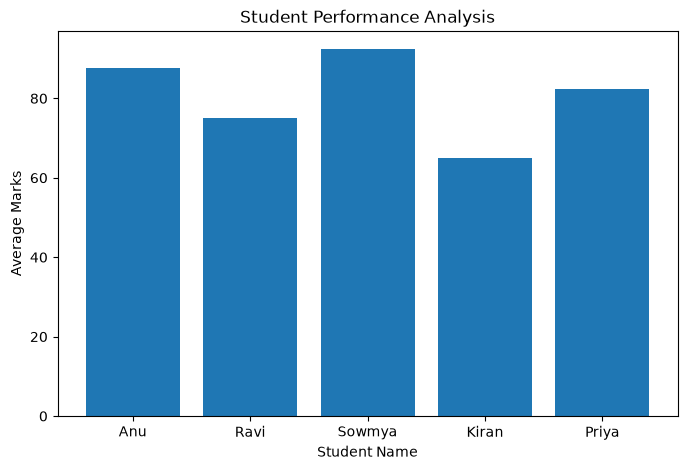

In [11]:
plt.figure(figsize=(8, 5))

plt.bar(df['Name'], df['Average'])

plt.xlabel("Student Name")
plt.ylabel("Average Marks")
plt.title("Student Performance Analysis")

plt.show()

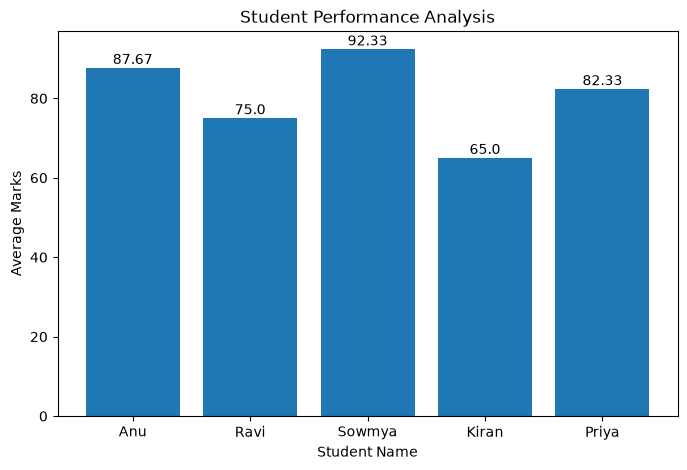

In [12]:
plt.figure(figsize=(8, 5))

plt.bar(df['Name'], df['Average'])

plt.xlabel("Student Name")
plt.ylabel("Average Marks")
plt.title("Student Performance Analysis")

for i, value in enumerate(df['Average']):
    plt.text(i, value + 1, round(value, 2), ha='center')

plt.show()


In [13]:
subject_avg = df[['Maths', 'Science', 'English']].mean()

print("Subject-wise Average Marks:")
print(subject_avg)

Subject-wise Average Marks:
Maths      78.0
Science    81.4
English    82.0
dtype: float64


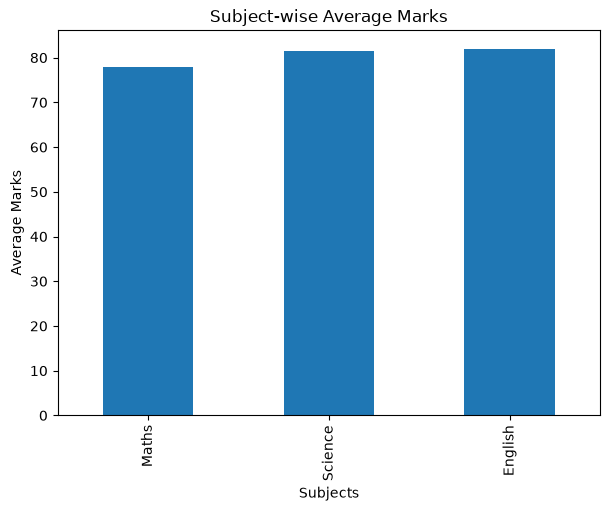

In [14]:
plt.figure(figsize=(7, 5))

subject_avg.plot(kind='bar')

plt.title("Subject-wise Average Marks")
plt.xlabel("Subjects")
plt.ylabel("Average Marks")

plt.show()


In [15]:
# Correlation Analysis

correlation = df[['Maths', 'Science', 'English']].corr()

print(correlation)



            Maths   Science   English
Maths    1.000000  0.974273  0.963600
Science  0.974273  1.000000  0.973657
English  0.963600  0.973657  1.000000


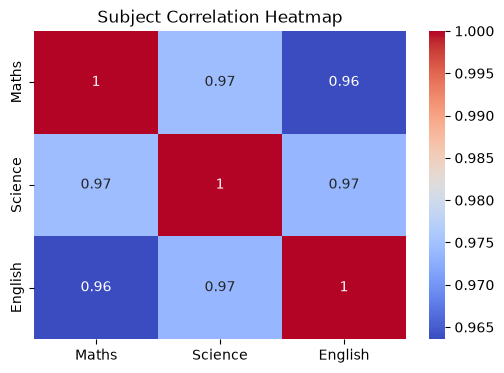

In [16]:
plt.figure(figsize=(6, 4))

sns.heatmap(correlation, annot=True, cmap='coolwarm')

plt.title("Subject Correlation Heatmap")

plt.show()


In [17]:
import numpy as np

df['Performance'] = np.where(
    df['Average'] >= 80, 'Excellent',
    np.where(df['Average'] >= 70, 'Good', 'Needs Improvement')
)

print(df[['Name', 'Average', 'Performance']])


     Name    Average        Performance
0     Anu  87.666667          Excellent
1    Ravi  75.000000               Good
2  Sowmya  92.333333          Excellent
3   Kiran  65.000000  Needs Improvement
4   Priya  82.333333          Excellent


Performance
Excellent            3
Good                 1
Needs Improvement    1
Name: count, dtype: int64


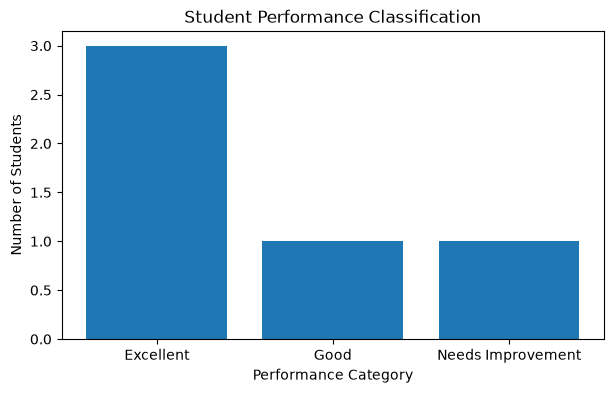

In [18]:
# Count students in each category

performance_count = df['Performance'].value_counts()

print(performance_count)

# Create Bar Graph

plt.figure(figsize=(7, 4))

plt.bar(performance_count.index, performance_count.values)

plt.title("Student Performance Classification")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")

plt.show()


In [19]:
X = df[['Maths', 'Science', 'English']]

y = df['Average']

print("Input Data:")
print(X)

print("Output Data:")
print(y)

Input Data:
   Maths  Science  English
0     85       90       88
1     70       75       80
2     95       92       90
3     60       65       70
4     80       85       82
Output Data:
0    87.666667
1    75.000000
2    92.333333
3    65.000000
4    82.333333
Name: Average, dtype: float64


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4, 3)
Testing Data: (1, 3)


In [21]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [22]:
y_pred = model.predict(X_test)

print("Predicted Average Marks:")
print(y_pred)

Predicted Average Marks:
[75.]


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate MAE
mae = mean_absolute_error(y_test, y_pred)

# Calculate MSE
mse = mean_squared_error(y_test, y_pred)

# Display results
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)

# Calculate R2 Score
if len(y_test) >= 2:
    r2 = r2_score(y_test, y_pred)
    print("R2 Score:", r2)
else:
    print("R2 Score needs at least 2 test samples")

Mean Absolute Error: 1.4210854715202004e-14
Mean Squared Error: 2.0194839173657902e-28
R2 Score needs at least 2 test samples


In [24]:
new_student = pd.DataFrame({
    'Maths': [80],
    'Science': [85],
    'English': [90]
})

prediction = model.predict(new_student)

print("Predicted Average Marks:", prediction[0])

Predicted Average Marks: 85.00000000000001


In [25]:
result = pd.DataFrame({
    "Actual Marks": y_test,
    "Predicted Marks": y_pred
})

In [26]:
result.to_csv("student_performance_results.csv", index=False)

print("File saved successfully!")

File saved successfully!


In [27]:
import pandas as pd

saved_result = pd.read_csv("student_performance_results.csv")

print(saved_result)

   Actual Marks  Predicted Marks
0          75.0             75.0


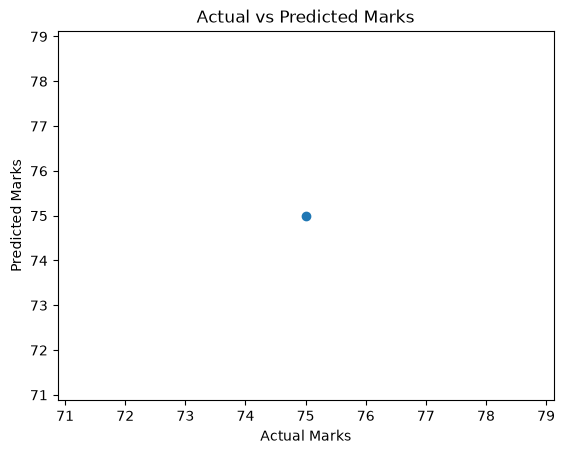

In [28]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")

plt.title("Actual vs Predicted Marks")

plt.show()

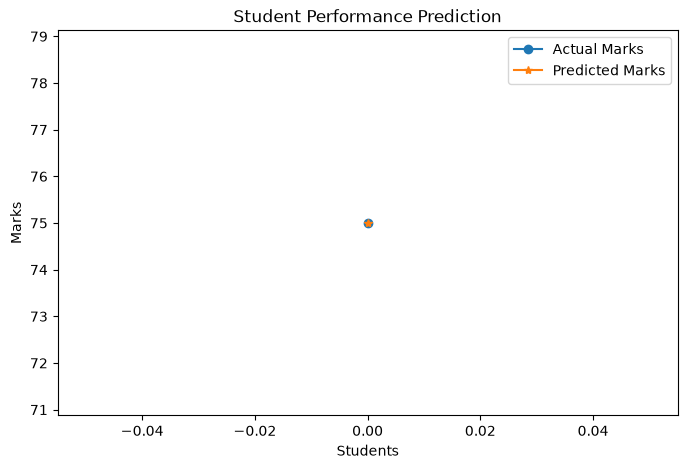

In [29]:
plt.figure(figsize=(8,5))

plt.plot(y_test.values, label="Actual Marks", marker="o")
plt.plot(y_pred, label="Predicted Marks", marker="*")

plt.xlabel("Students")
plt.ylabel("Marks")

plt.title("Student Performance Prediction")

plt.legend()
plt.show()

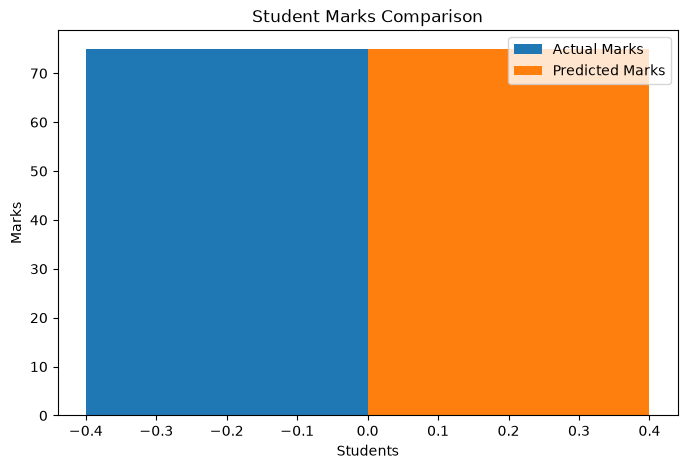

In [30]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(y_test))

plt.figure(figsize=(8,5))

plt.bar(x - 0.2, y_test, 0.4, label="Actual Marks")
plt.bar(x + 0.2, y_pred, 0.4, label="Predicted Marks")

plt.xlabel("Students")
plt.ylabel("Marks")

plt.title("Student Marks Comparison")

plt.legend()
plt.show()

In [31]:
print("STUDENT PERFORMANCE DASHBOARD")

print("Total Students:", len(y_test))

print("Average Marks:", np.mean(y_test))

print("Highest Marks:", np.max(y_test))

print("Lowest Marks:", np.min(y_test))

print("Average Predicted Marks:", np.mean(y_pred))

STUDENT PERFORMANCE DASHBOARD
Total Students: 1
Average Marks: 75.0
Highest Marks: 75.0
Lowest Marks: 75.0
Average Predicted Marks: 75.00000000000001


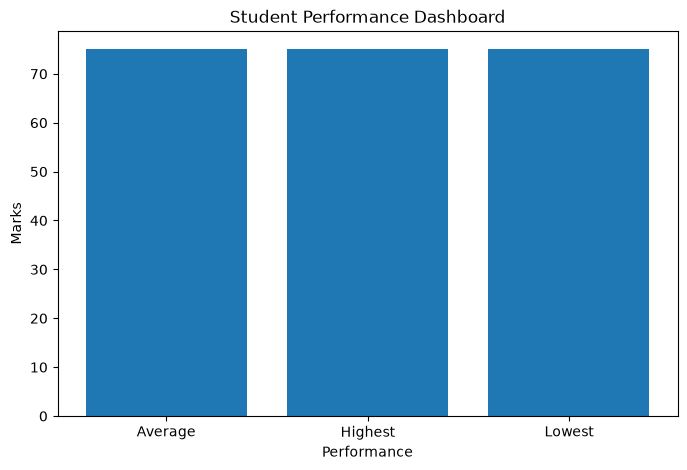

In [32]:
import matplotlib.pyplot as plt

labels = ["Average", "Highest", "Lowest"]
values = [
    np.mean(y_test),
    np.max(y_test),
    np.min(y_test)
]

plt.figure(figsize=(8,5))

plt.bar(labels, values)

plt.title("Student Performance Dashboard")
plt.xlabel("Performance")
plt.ylabel("Marks")

plt.show()

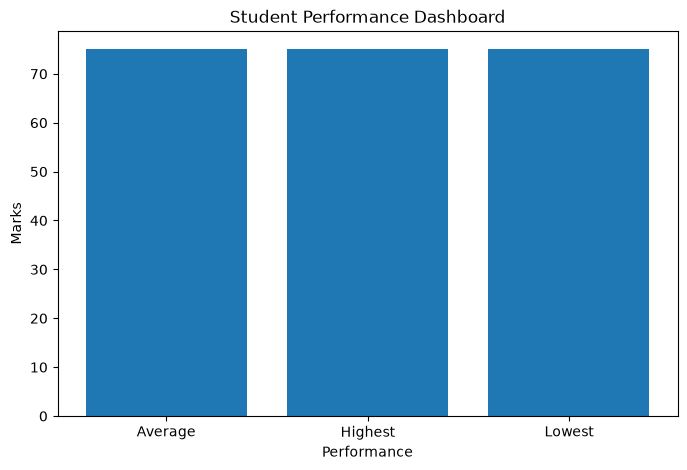

In [33]:
plt.figure(figsize=(8,5))

plt.bar(labels, values)

plt.title("Student Performance Dashboard")
plt.xlabel("Performance")
plt.ylabel("Marks")

plt.savefig("student_dashboard.png")

plt.show()

In [34]:
%whos

Variable              Type                Data/Info
---------------------------------------------------
LinearRegression      ABCMeta             <class 'sklearn.linear_mo<...>._base.LinearRegression'>
X                     DataFrame           Shape: (5, 3)
X_test                DataFrame           Shape: (1, 3)
X_train               DataFrame           Shape: (4, 3)
correlation           DataFrame           Shape: (3, 3)
data                  dict                n=4
df                    DataFrame           Shape: (5, 7)
i                     int                 4
labels                list                n=3
lowest                Series              Shape: (6,)
mae                   float               1.4210854715202004e-14
mean_absolute_error   function            <function mean_absolute_e<...>or at 0x000001D8184FA090>
mean_squared_error    function            <function mean_squared_er<...>or at 0x000001D8184FA4B0>
model                 LinearRegression    LinearRegression()
mse   

In [35]:
print("Student Input Columns:")
print(X.columns)

print("\nNew Student Details:")
print(new_student)

Student Input Columns:
Index(['Maths', 'Science', 'English'], dtype='str')

New Student Details:
   Maths  Science  English
0     80       85       90


In [36]:
new_student = pd.DataFrame({
    "Maths": [80],
    "Science": [85],
    "English": [90]
})

prediction = model.predict(new_student)

print("New Student Details:")
print(new_student)

print("\nPredicted Average Marks:", prediction[0])

New Student Details:
   Maths  Science  English
0     80       85       90

Predicted Average Marks: 85.00000000000001


In [37]:
new_student = pd.DataFrame({
    "Maths": [60],
    "Science": [70],
    "English": [80]
})

prediction = model.predict(new_student)

print("Predicted Average Marks:", prediction[0])

Predicted Average Marks: 70.00000000000003


In [39]:
maths = float(input("Enter Maths Marks: "))
science = float(input("Enter Science Marks: "))
english = float(input("Enter English Marks: "))

new_student = pd.DataFrame({
    "Maths": [maths],
    "Science": [science],
    "English": [english]
})

prediction = model.predict(new_student)

print("\nPredicted Average Marks:", round(prediction[0], 2))

Enter Maths Marks:  91
Enter Science Marks:  84
Enter English Marks:  91



Predicted Average Marks: 88.67


In [40]:
import matplotlib.pyplot as plt
import pandas as pd

In [41]:
data = {
    'Student': ['S1', 'S2', 'S3', 'S4', 'S5'],
    'Maths': [80, 70, 90, 60, 85],
    'Science': [85, 75, 95, 65, 80],
    'English': [90, 80, 85, 70, 90]
}

df = pd.DataFrame(data)

print(df)

  Student  Maths  Science  English
0      S1     80       85       90
1      S2     70       75       80
2      S3     90       95       85
3      S4     60       65       70
4      S5     85       80       90


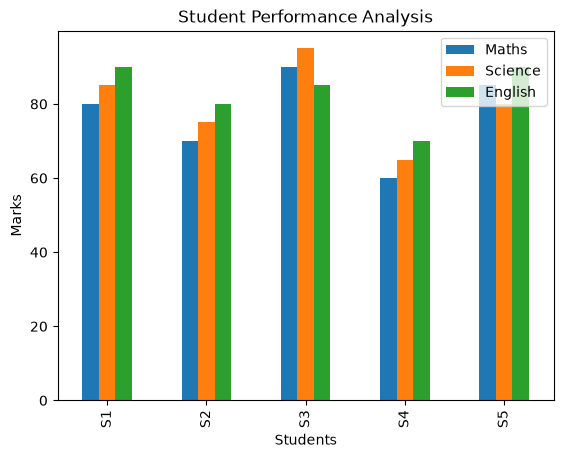

In [42]:
df.plot(
    x='Student',
    y=['Maths', 'Science', 'English'],
    kind='bar'
)

plt.title('Student Performance Analysis')
plt.xlabel('Students')
plt.ylabel('Marks')
plt.show()

In [43]:
df['Total'] = df['Maths'] + df['Science'] + df['English']

print(df)

  Student  Maths  Science  English  Total
0      S1     80       85       90    255
1      S2     70       75       80    225
2      S3     90       95       85    270
3      S4     60       65       70    195
4      S5     85       80       90    255


In [44]:
df['Average'] = df[['Maths', 'Science', 'English']].mean(axis=1)

print(df)

  Student  Maths  Science  English  Total  Average
0      S1     80       85       90    255     85.0
1      S2     70       75       80    225     75.0
2      S3     90       95       85    270     90.0
3      S4     60       65       70    195     65.0
4      S5     85       80       90    255     85.0


In [45]:
highest = df.loc[df['Total'].idxmax()]

lowest = df.loc[df['Total'].idxmin()]

print("Top Performer:")
print(highest)

print("\nLowest Performer:")
print(lowest)

Top Performer:
Student      S3
Maths        90
Science      95
English      85
Total       270
Average    90.0
Name: 2, dtype: object

Lowest Performer:
Student      S4
Maths        60
Science      65
English      70
Total       195
Average    65.0
Name: 3, dtype: object


In [46]:
import seaborn as sns
import matplotlib.pyplot as plt

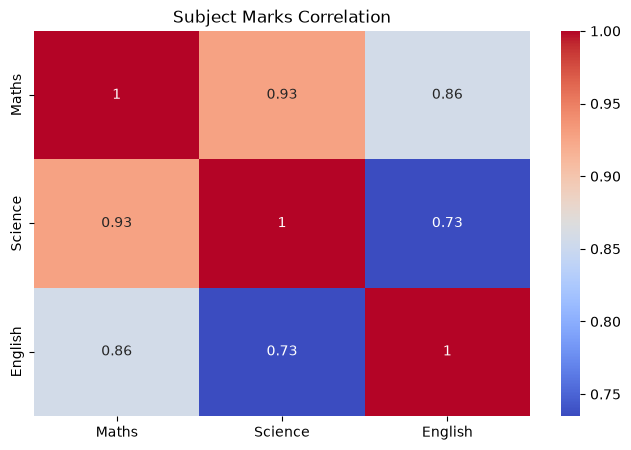

In [47]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df[['Maths', 'Science', 'English']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Subject Marks Correlation')
plt.show()